## 1. Libraries and Setup

Import the libraries used for data handling, visualization, preprocessing, machine learning, and evaluation.


In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , OrdinalEncoder , OneHotEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report , confusion_matrix

## 2. Load the Datasets

Read the CSV files into pandas DataFrames so the data can be inspected and prepared for analysis.


In [42]:
X_df = pd.read_csv(r"C:\Users\DELL\Downloads\train.csv")
df = pd.read_csv(r"C:\Users\DELL\Downloads\test.csv")

## 3. Preview the Dataset

`head()` displays the first rows of the dataset. This helps review the columns and understand the values before preprocessing.


In [43]:
X_df.head(30)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


## 4. Dataset Information

`info()` shows the number of rows, column names, data types, and non-null counts. It helps identify columns with missing values or unexpected data types.


In [44]:
X_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## 5. Check Duplicate Rows

Count duplicate rows while excluding `PassengerId` from the comparison, because it is a unique identifier and should not hide otherwise identical records.


In [82]:
duplicate_count = X_df.drop(
    columns=["PassengerId"]
).duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


## 6. Summary Statistics

`describe()` provides summary statistics for numerical columns, including count, mean, standard deviation, minimum, quartiles, and maximum. These statistics help identify unusual ranges and possible outliers.


In [46]:
X_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 7. Check Dataset Shape

`shape` returns the number of rows and columns. It can be used to track dataset size during preprocessing.


In [47]:
X_df.shape

(891, 12)

## 8. Count Missing Values

`isnull().sum()` counts missing values in each column. This helps identify which columns need missing-value treatment.


In [48]:
X_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 9. Inspect Cabin Missingness

Calculate the percentage of missing values in `Cabin`. The result helps decide whether to drop the column or extract useful information from it.


In [49]:
X_df["Cabin"].isnull().mean() * 100

np.float64(77.10437710437711)

## 10. Separate Features and Target

Separate the input features (`X`) from the target (`y`). The target contains the value the model is expected to predict.


In [50]:
X = X_df.drop(["Survived","PassengerId"], axis=1)
y = X_df["Survived"]

## 11. Drop Name and Ticket

Remove `Name` and `Ticket` from the feature set because these text columns are not used directly in this workflow.


In [51]:
X = X.drop(["Name", "Ticket"] , axis=1)

## 12. Inspect Target Distribution

`value_counts()` counts the examples in each target class. This helps identify possible class imbalance before training.


In [52]:
y.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

## 13. Handle Cabin

Create a `HasCabin` indicator if you want to preserve whether a cabin value was available; alternatively, remove `Cabin` if it is not being used. This note describes the purpose of the existing code and does not change it.


In [53]:
X.drop(columns=["Cabin"] , inplace=True)

## 14. Review Feature Columns

Display the remaining feature names to verify which columns are available for the next preprocessing steps.


In [54]:
X.columns

Index(['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'], dtype='object')

## 15. Split Training and Testing Data

`train_test_split()` separates the data into training and testing sets. The training set is used to fit models, while the testing set evaluates performance on unseen examples.


In [55]:
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
) 

## 16. Impute Missing Values in Training Data

Fill missing numeric values using a statistic such as the mean, and missing categorical values using the most frequent category. Fit these choices using training data only.


In [56]:
for column in X_train.columns:
    if X_train[column].dtype in ["int64" , "float64"]:
         X_train[column] = X_train[column].fillna(X_train[column].mean())
    elif X_train[column].dtype == "object":
         X_train[column] = X_train[column].fillna(X_train[column].mode() [0])     

## 17. Verify Training Missing Values

Check the number of missing values after imputation to confirm whether the training features have been filled successfully.


In [57]:
X_train.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

## 18. Impute Missing Values in Testing Data

Apply the imputation values learned from the training data to the test set. Do not calculate new imputation statistics from the test set.


In [58]:
for column in X_test.columns:
    if X_test[column].dtype in ["int64" , "float64"]:
        X_test[column] = X_test[column].fillna(X_train[column].mean())
    elif X_test[column].dtype == "object":
        X_test[column] = X_test[column].fillna(X_train[column].mode()[0])

## 19. Verify Testing Missing Values

Check whether any missing values remain in the test features after imputation.


In [59]:
X_test.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

## 20. Measure Skewness

`skew()` measures the asymmetry of numeric feature distributions. Positive values indicate a longer right tail, while negative values indicate a longer left tail.


In [60]:
print(X_train.skew(numeric_only=True))
print(X_test.skew(numeric_only=True))

Pclass   -0.677419
Age       0.369103
SibSp     3.619385
Parch     2.695459
Fare      4.875066
dtype: float64
Pclass   -0.453067
Age       0.745114
SibSp     2.441650
Parch     2.912513
Fare      3.294218
dtype: float64


## 21. Plot Numeric Distributions

Histograms and density curves show the shapes of numeric distributions. Use these plots to inspect skewness and potential extreme values.


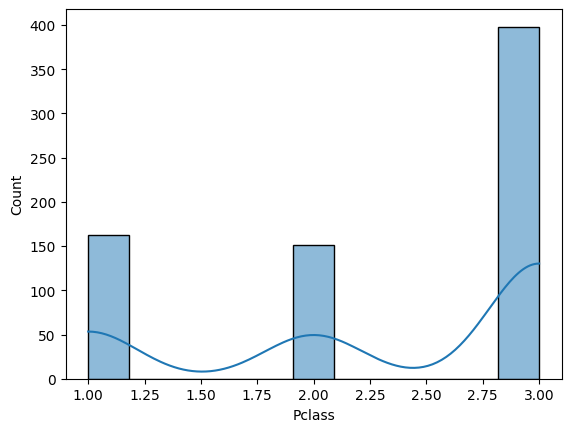

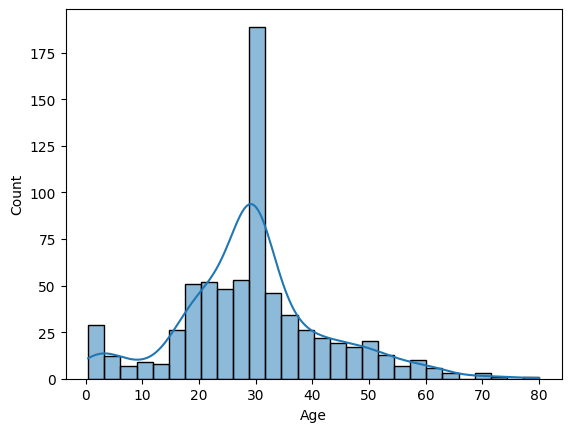

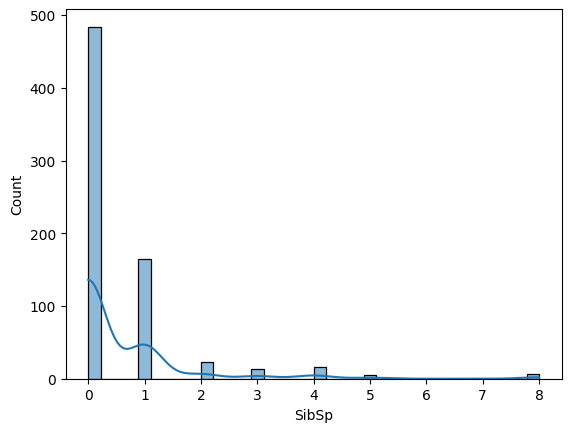

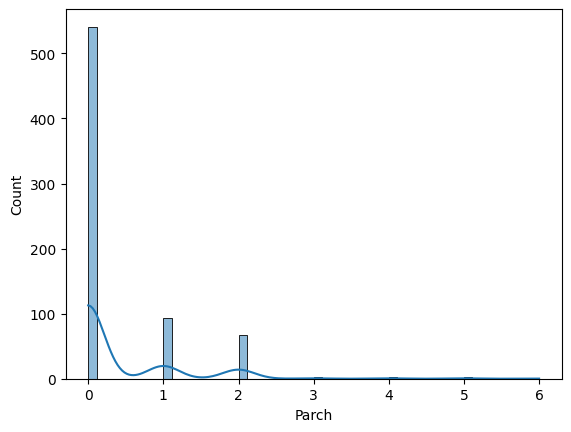

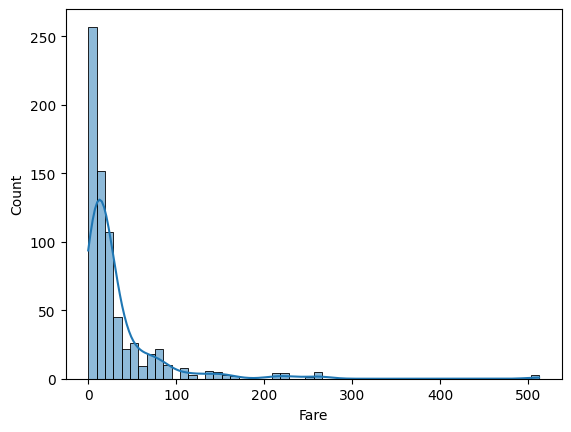

In [61]:
for name in X_train.columns:
    if X_train[name].dtype in ["int64" , "float64"]:
        sns.histplot(X_train[name] , kde=True)
        plt.show()

## 22. Transform Skewed Features

`log1p(x)` calculates `log(1 + x)` and can reduce right skew in suitable non-negative features. Compare the distribution before and after applying the transformation.


In [62]:
###### handll Skew in Train #######
X_train["SibSp_log"] = np.log1p(X_train["SibSp"])
X_train["Parch_log"] = np.log1p(X_train["Parch"])
X_train["Fare_log"] = np.log1p(X_train["Fare"])

###### handll Skew in test ########
X_test["SibSp_log"] = np.log1p(X_test["SibSp"])
X_test["Parch_log"] = np.log1p(X_test["Parch"])
X_test["Fare_log"] = np.log1p(X_test["Fare"])

## 23. Remove Original Columns

Remove original columns only when their transformed versions are intended to replace them. Check that the transformed features retain the information needed by the model.


In [63]:
X_train.drop(columns=["SibSp" , "Parch" , "Fare"] , inplace=True)
X_test.drop(columns=["SibSp" , "Parch" , "Fare"] , inplace=True)

## 24. Compare Skewness After Transformation

Recalculate skewness after the transformation and compare it with the original values to see whether the distribution became less skewed.


In [64]:
print(X_train.skew(numeric_only=True))
print("-" * 50)
print(X_test.skew(numeric_only=True))

Pclass      -0.677419
Age          0.369103
SibSp_log    1.677430
Parch_log    1.644045
Fare_log     0.403554
dtype: float64
--------------------------------------------------
Pclass      -0.453067
Age          0.745114
SibSp_log    1.363838
Parch_log    1.804079
Fare_log     0.366900
dtype: float64


## 25. Review Transformed Distributions

Plot the numeric distributions again to visually compare their shapes after transformation.


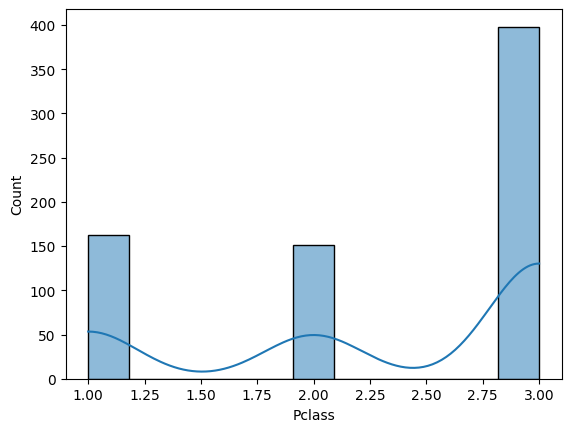

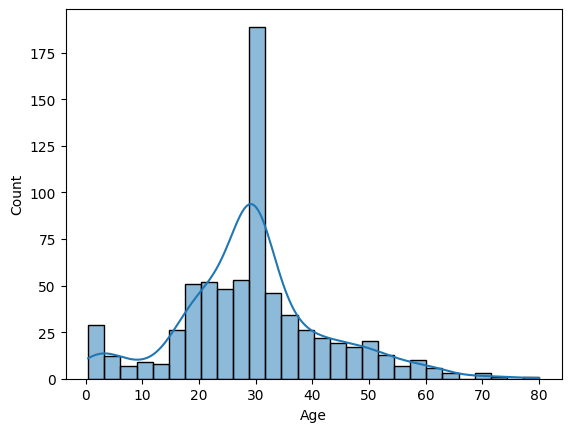

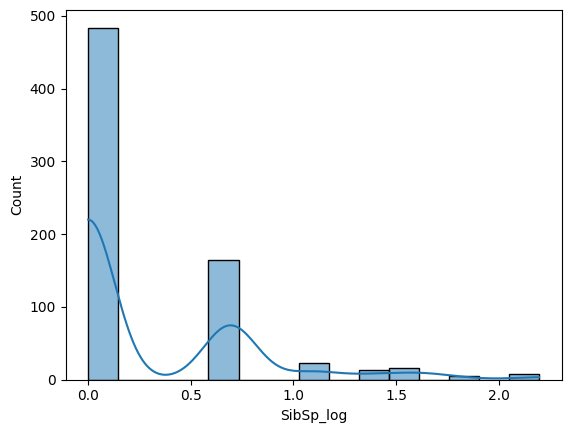

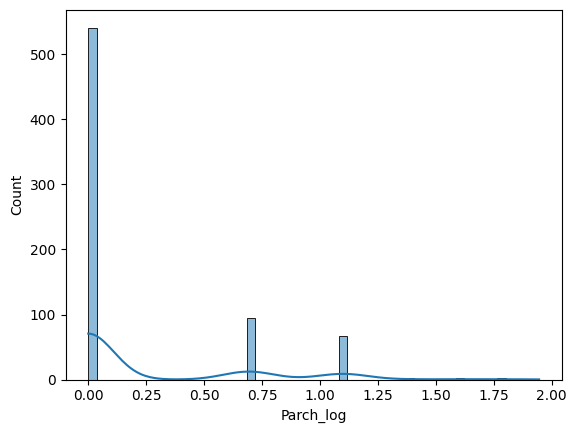

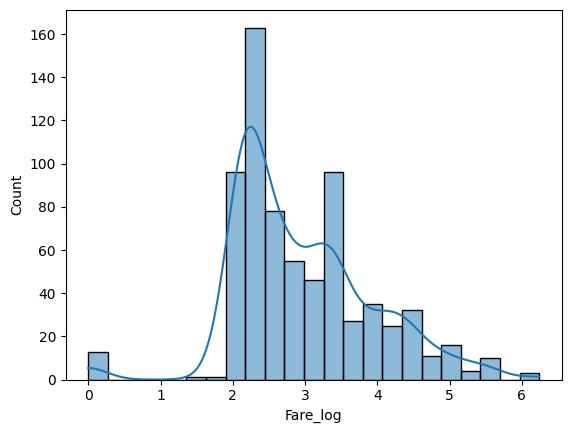

In [65]:
for name in X_train.columns:
    if X_train[name].dtype in ["int64" , "float64"]:
        sns.histplot(X_train[name] , kde=True)
        plt.show()

## 26. Create New Features

Feature engineering creates additional useful variables from existing columns. Examples include family size, whether a passenger travelled alone, and fare per person.


In [66]:
# Feature Engineering on X_train
X_train["FamilySize"] = (
    X_train["SibSp_log"] + X_train["Parch_log"] + 1
)

X_train["IsAlone"] = (
    X_train["FamilySize"] == 1
).astype(int)

X_train["FarePerPerson"] = (
    X_train["Fare_log"] /
    X_train["FamilySize"]
)


# Feature Engineering on X_test
X_test["FamilySize"] = (
    X_test["SibSp_log"] + X_test["Parch_log"] + 1
)

X_test["IsAlone"] = (
    X_test["FamilySize"] == 1
).astype(int)

X_test["FarePerPerson"] = (
    X_test["Fare_log"] /
    X_test["FamilySize"]
)

## 27. Select Numeric Columns

Select numeric columns for outlier analysis because the IQR method relies on numerical quartiles.


In [67]:
numerical_columns = X_train.select_dtypes(include=[np.number]).columns
print(f"numerical columns:{numerical_columns}")

numerical columns:Index(['Pclass', 'Age', 'SibSp_log', 'Parch_log', 'Fare_log', 'FamilySize',
       'IsAlone', 'FarePerPerson'],
      dtype='object')


## 28. Calculate Quartiles and IQR

The first quartile (`Q1`) is the 25th percentile and the third quartile (`Q3`) is the 75th percentile. The interquartile range is `IQR = Q3 - Q1`.


In [68]:
Q1 = X_train[numerical_columns].quantile(0.25)
Q3 = X_train[numerical_columns].quantile(0.75)
IQR = Q3 - Q1



## 29. Define Outlier Bounds

The common IQR rule defines lower and upper bounds as `Q1 - 1.5 × IQR` and `Q3 + 1.5 × IQR`. Values outside these bounds are potential outliers, not automatically data errors.


In [69]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

## 30. Inspect Outliers

Identify values outside the IQR bounds. Calculate the bounds from the training data and use those same bounds when inspecting the test data.


In [70]:
def Xtrain():
    for com in X_train[numerical_columns]:
        outliers_below = X_train[com] < lower_bound[com]
        outliers_above = X_train[com] > upper_bound[com]
        if outliers_below.any():
            print(f"outliers below lower bound in columns : {com}")
            print(X_train.loc[outliers_below , com])

        elif outliers_above.any():
            print(f"outliers above upper bound in columns : {com}")
            print(X_train.loc[outliers_above , com])
        else:
            print(f"no outliers in column : {com}")
            continue
def Xtest():
    for com in X_test[numerical_columns]:
        outliers_below = X_test[com] < lower_bound[com]
        outliers_above = X_test[com] > upper_bound[com]
        if outliers_below.any():
            print(f"outliers below lower bound in columns : {com}")
            print(X_test.loc[outliers_below , com])
        elif outliers_above.any():
            print(f"outliers above upper bound in columns : {com}")
            print(X_test.loc[outliers_above , com])
        else:
            print(f"no outliers in column : {com}")
            continue


Xtrain()                         

no outliers in column : Pclass
outliers below lower bound in columns : Age
7      2.00
305    0.92
172    1.00
164    1.00
381    1.00
644    0.75
530    2.00
340    2.00
827    1.00
479    2.00
16     2.00
469    0.75
119    2.00
297    2.00
183    1.00
788    1.00
386    1.00
824    2.00
803    0.42
755    0.67
642    2.00
205    2.00
831    0.83
Name: Age, dtype: float64
outliers above upper bound in columns : SibSp_log
324    2.197225
59     1.791759
792    2.197225
180    2.197225
480    1.791759
386    1.791759
863    2.197225
846    2.197225
159    2.197225
683    1.791759
201    2.197225
71     1.791759
Name: SibSp_log, dtype: float64
outliers above upper bound in columns : Parch_log
813    1.098612
118    0.693147
595    0.693147
259    0.693147
542    1.098612
         ...   
160    0.693147
871    0.693147
71     1.098612
435    1.098612
102    0.693147
Name: Parch_log, Length: 171, dtype: float64
outliers below lower bound in columns : Fare_log
302    0.0
633    0.0
597    

## 31. Run the Test Outlier Check

Run the outlier inspection for the test features. This step checks values; it does not necessarily modify them.


In [71]:
Xtest()

no outliers in column : Pclass
outliers below lower bound in columns : Age
78    0.83
Name: Age, dtype: float64
no outliers in column : SibSp_log
outliers above upper bound in columns : Parch_log
709    0.693147
720    0.693147
136    1.098612
485    0.693147
853    0.693147
819    1.098612
63     1.098612
362    0.693147
86     1.386294
659    1.098612
448    0.693147
820    0.693147
360    1.609438
802    1.098612
585    1.098612
299    0.693147
446    0.693147
532    0.693147
312    0.693147
311    1.098612
835    0.693147
539    1.098612
254    1.098612
266    0.693147
319    0.693147
165    1.098612
541    1.098612
670    0.693147
323    0.693147
736    1.386294
529    0.693147
78     1.098612
65     0.693147
885    1.791759
416    0.693147
657    0.693147
54     0.693147
97     0.693147
417    1.098612
852    0.693147
25     1.791759
10     0.693147
Name: Parch_log, dtype: float64
outliers below lower bound in columns : Fare_log
822    0.0
481    0.0
Name: Fare_log, dtype: float6

## 32. Treat Outliers

Clipping replaces values outside chosen bounds with the nearest bound. Apply it only to features for which this treatment is appropriate; do not automatically clip every numeric column.


In [72]:
for com in X_train[numerical_columns]:
    X_train[com] = np.where(X_train[com] < lower_bound[com] , lower_bound[com] , np.where(X_train[com] > upper_bound[com] , upper_bound[com] , X_train[com]))

for coms in X_test[numerical_columns]:
    X_test[coms] = np.where(X_test[coms] < lower_bound[coms] , lower_bound[coms] , np.where(X_test[coms] > upper_bound[coms] , upper_bound[coms] , X_test[coms]))
        

## 33. Verify Outlier Treatment

Inspect the features again after outlier treatment to check whether values remain outside the selected bounds.


In [73]:
Xtrain()
print("-" * 50)
Xtest()

no outliers in column : Pclass
no outliers in column : Age
no outliers in column : SibSp_log
no outliers in column : Parch_log
no outliers in column : Fare_log
no outliers in column : FamilySize
no outliers in column : IsAlone
no outliers in column : FarePerPerson
--------------------------------------------------
no outliers in column : Pclass
no outliers in column : Age
no outliers in column : SibSp_log
no outliers in column : Parch_log
no outliers in column : Fare_log
no outliers in column : FamilySize
no outliers in column : IsAlone
no outliers in column : FarePerPerson


## 34. One-Hot Encode Embarked

`OneHotEncoder` converts categories in `Embarked` into separate indicator columns. Fit the encoder on training data and use the learned categories to transform test data.


In [74]:
cat_col = ["Embarked"]
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_one = encoder.fit_transform(X_train[cat_col])
X_test_one = encoder.transform(X_test[cat_col])

encoded_cols = encoder.get_feature_names_out(cat_col)

X_train_one = pd.DataFrame(
    X_train_one,
    columns=encoded_cols,
    index=X_train.index
)

X_test_one = pd.DataFrame(
    X_test_one,
    columns=encoded_cols,
    index=X_test.index
)

X_train = pd.concat([X_train.drop(columns=cat_col) , X_train_one] , axis=1)
X_test = pd.concat([X_test.drop(columns=cat_col) , X_test_one] , axis=1)

## 35. Preview Encoded Features

Display the transformed training features to verify that the encoding created the expected columns.


In [75]:
X_train.head()

,Pclass,Sex,Age,SibSp_log,Parch_log,Fare_log,FamilySize,IsAlone,FarePerPerson,Embarked_C,Embarked_Q,Embarked_S
331,1.0,male,45.5,0.000000,0.0,3.384390,1.000000,1.0,3.384390,0.0,0.0,1.0
733,2.0,male,23.0,0.000000,0.0,2.639057,1.000000,1.0,2.639057,0.0,0.0,1.0
382,3.0,male,32.0,0.000000,0.0,2.188856,1.000000,1.0,2.188856,0.0,0.0,1.0
704,3.0,male,26.0,0.693147,0.0,2.180892,1.693147,0.0,1.288070,0.0,0.0,1.0
813,3.0,female,6.0,1.609438,0.0,3.474293,2.732868,0.0,0.936960,0.0,0.0,1.0


## 36. Encode Remaining Categorical Features

Convert remaining text categories into numeric representations. Learn category mappings from training data and reuse them for the test data.


In [76]:
cat_cols = X_train.select_dtypes(include="object").columns
enc = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train[cat_cols] = enc.fit_transform(X_train[cat_cols])
X_test[cat_cols] = enc.transform(X_test[cat_cols])

## 37. Check Data Types

`info()` shows the resulting column types and non-null counts. Confirm that the features are in a format suitable for the selected models.


In [77]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 331 to 102
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pclass         712 non-null    float64
 1   Sex            712 non-null    float64
 2   Age            712 non-null    float64
 3   SibSp_log      712 non-null    float64
 4   Parch_log      712 non-null    float64
 5   Fare_log       712 non-null    float64
 6   FamilySize     712 non-null    float64
 7   IsAlone        712 non-null    float64
 8   FarePerPerson  712 non-null    float64
 9   Embarked_C     712 non-null    float64
 10  Embarked_Q     712 non-null    float64
 11  Embarked_S     712 non-null    float64
dtypes: float64(12)
memory usage: 72.3 KB


## 38. Preview Test Features

Inspect the test features after preprocessing and confirm that their columns correspond to the training features.


In [78]:
X_test.head()

,Pclass,Sex,Age,SibSp_log,Parch_log,Fare_log,FamilySize,IsAlone,FarePerPerson,Embarked_C,Embarked_Q,Embarked_S
709,3.0,1.0,29.498846,0.693147,0.0,2.787834,2.386294,0.0,1.168269,1.0,0.0,0.0
439,2.0,1.0,31.000000,0.000000,0.0,2.442347,1.000000,1.0,2.442347,0.0,0.0,1.0
840,3.0,1.0,20.000000,0.000000,0.0,2.188856,1.000000,1.0,2.188856,0.0,0.0,1.0
720,2.0,0.0,6.000000,0.000000,0.0,3.526361,1.693147,0.0,2.082725,0.0,0.0,1.0
39,3.0,0.0,14.000000,0.693147,0.0,2.504848,1.693147,0.0,1.479404,1.0,0.0,0.0


## 39. Check Class Distribution

Compare the target-class counts in the training and test sets. Stratified splitting helps preserve approximately the same class proportions in both sets.


In [79]:
print(y_train.value_counts())
print(y_test.value_counts())

Survived
0    444
1    268
Name: count, dtype: int64
Survived
0    105
1     74
Name: count, dtype: int64


## 40. Scale Numeric Features

`StandardScaler` standardizes features using the training set's mean and standard deviation. Fit it on training data, then use the same fitted scaler to transform test data.


In [80]:
stnd = StandardScaler()
X_train_stn = stnd.fit_transform(X_train)
X_test_stn = stnd.transform(X_test)

## 41. Train and Evaluate Models

Fit each classifier on the training data, predict the test labels, and compare metrics such as accuracy, precision, recall, F1-score, and the confusion matrix.


In [81]:
list_acc = {}

models = {
    "logistic_regression" : LogisticRegression(max_iter=2000,
                                               C=1.0),
    "Decision_tree" : DecisionTreeClassifier(
        max_depth=7,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
        
    ),
    "Random_Forest" : RandomForestClassifier(
        n_estimators=150,
        max_depth=5,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
        
    
    ),
    "KNN" : KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
        

    )
}

for name , model in  models.items():
    model.fit(X_train_stn,y_train)
    y_pre = model.predict(X_test_stn)
    acc = accuracy_score(y_test , y_pre)
    print(f"accuracy_score {name}: {acc}")
    list_acc[name] = acc

    print(f"\nClassification Report {name}:")
    print(classification_report(y_test, y_pre ))

    print(f"Confusion Matrix {name}:")
    print(confusion_matrix(y_test, y_pre))

acc_befor = pd.DataFrame({
    "acc" : list_acc
})
print(acc_befor)

    

accuracy_score logistic_regression: 0.8156424581005587

Classification Report logistic_regression:
              precision    recall  f1-score   support

           0       0.84      0.85      0.84       105
           1       0.78      0.77      0.78        74

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179

Confusion Matrix logistic_regression:
[[89 16]
 [17 57]]
accuracy_score Decision_tree: 0.8156424581005587

Classification Report Decision_tree:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       105
           1       0.80      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.81      0.82      0.81       179

Confusion Matrix Decision_tree:
[[91 14]
 [19 55]]
accuracy_score Random_Forest: 0.8044692737430168

Cl